# Wyzwanie 1
## Dane:
### Interesuję się perfumami, dlatego wybrałem zbiór danych z Fragrantiki (Kaggle).

In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer

In [19]:
df = pd.read_csv("fra_cleaned.csv", sep=";", encoding="cp1252")
df["Rating Value"] = df["Rating Value"].str.replace(",", ".").astype(float)

In [20]:
df

,url,Perfume,Brand,Country,Gender,Rating Value,Rating Count,Year,Top,Middle,Base,Perfumer1,Perfumer2,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5
0,https://www.fragrantica.com/perfume/xerjoff/ac...,accento-overdose-pride-edition,xerjoff,Italy,unisex,1.42,201,2022.0,"fruity notes, aldehydes, green notes","bulgarian rose, egyptian jasmine, lily-of-the-...","eucalyptus, pine",unknown,NaN,rose,woody,fruity,aromatic,floral
1,https://www.fragrantica.com/perfume/jean-paul-...,classique-pride-2024,jean-paul-gaultier,France,women,1.86,70,2024.0,"yuzu, citruses","orange blossom, neroli","musk, blonde woods",unknown,NaN,citrus,white floral,sweet,fresh,musky
2,https://www.fragrantica.com/perfume/jean-paul-...,classique-pride-2023,jean-paul-gaultier,France,unisex,1.91,285,2023.0,"blood orange, yuzu","neroli, orange blossom","musk, white woods",natalie gracia-cetto,quentin bisch,citrus,white floral,sweet,fresh spicy,musky
3,https://www.fragrantica.com/perfume/bruno-bana...,pride-edition-man,bruno-banani,Germany,men,1.92,59,2019.0,"guarana, grapefruit, red apple","walnut, lavender, guava","vetiver, benzoin, amber",unknown,NaN,fruity,nutty,woody,tropical,NaN
4,https://www.fragrantica.com/perfume/jean-paul-...,le-male-pride-collector,jean-paul-gaultier,France,men,1.93,632,2020.0,"mint, lavender, cardamom, artemisia, bergamot","caraway, cinnamon, orange blossom","vanilla, sandalwood, amber, cedar, tonka bean",francis kurkdjian,NaN,aromatic,warm spicy,fresh spicy,cinnamon,vanilla
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24058,https://www.fragrantica.com/perfume/o-boticari...,floratta,o-boticario,Brazil,women,4.81,31,1992.0,"ozonic notes, peach","lily-of-the-valley, jasmine","musk, amber",thierry lecoule,NaN,white floral,ozonic,fresh,musky,powdery
24059,https://www.fragrantica.com/perfume/sultan-pas...,cheval-d-arabie,sultan-pasha-attars,UK,unisex,4.81,26,2020.0,"taif rose, indian oud, white rose, olibanum, e...","bulgarian rose, indian oud, hay, leather, cive...","white amber, leather, hay, elemi resin, kyara ...",sultan pasha,NaN,rose,amber,fresh spicy,animalic,aromatic
24060,https://www.fragrantica.com/perfume/darkbeat-p...,khaox,darkbeat-parfums,Spain,unisex,4.85,26,2020.0,"mint, lime, rum","lily-of-the-valley, fig leaf, cardamom","musk, oakmoss, amber, patchouli",josé m. giraldo,NaN,green,aromatic,citrus,fresh spicy,woody
24061,https://www.fragrantica.com/perfume/parfumerie...,aoud-no-1,parfumerie-bruckner,Germany,unisex,4.86,28,2011.0,"apple, peach, saffron","plum, orange blossom, jasmine","agarwood (oud), sandalwood, vanilla",unknown,NaN,fruity,sweet,oud,woody,powdery


### Liczba perfum w podziale na płeć

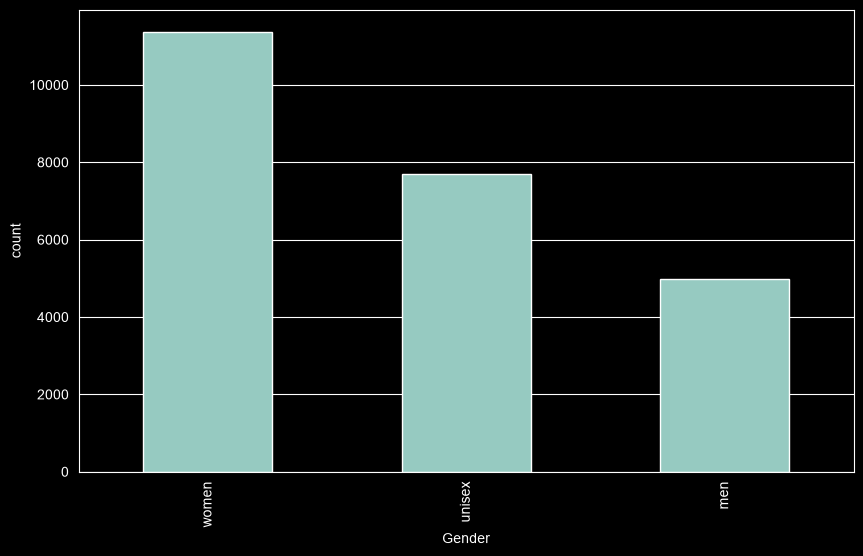

In [21]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Gender", order=df["Gender"].value_counts().index, width=0.5)

plt.xticks(rotation=90)
plt.show()

#### Jakie hipotezy można postawić na podstawie tych danych?

In [22]:
# 1) Model z łatwością odróżni perfumy męskie od damskich, ale będzie miał problem z rozpoznaniem perfum unisex.
# Plan sprawdzenia hipotezy: model 1 - perfumy men/women, model 2 - perfumy men/women/unisex
#

# Data leakage: dane takie jak nazwa czy url
# Problem z danymi: niektóre nuty są bardzo specyficzne i występują tylko w jednych perfumach.
# Problem z danymi: miejscami brakuje informacji (np. niektórych nut czy roku premiery) -> dla uproszczenia pomijam kolumny main accord i rok, więc braki w nich nie mają znaczenia.
#

#### Do weryfikacji hipotezy użyję regresji logistycznej, bo dobrze sprawdza się w klasyfikacji.
Najpierw muszę przekształcić dane (one-hot encoding nut).

In [23]:
#tasowanie bo w danych perfumy są poukładane według oceny
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df["nuty"] = df.apply(
    lambda r: [n.strip().lower()
               for kol in ["Top", "Middle", "Base"]
               for n in str(r[kol]).split(",") if n.strip()],
    axis=1
)

mlb = MultiLabelBinarizer()
dane = pd.DataFrame(
    mlb.fit_transform(df["nuty"]),
    columns=mlb.classes_,
    index=[f"perfum{i}" for i in range(len(df))]
)

y = pd.Series(df["Rating Value"].values, index=dane.index)


In [24]:
dane

,absinthe,acai berry,accord eudora®,acerola,acerola blossom,acetylfuran,acácia,african freesia petals,african geranium,african ginger,...,yellow rose,yellow water lily,ylang ylang,ylang-ylang,yogurt,yohimbe,yuzu,yuzu flower,zefir,zinnia
perfum0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
perfum3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
perfum24058,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum24059,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum24060,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum24061,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Z tak przygotowanymi danymi można zacząć trening :)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

y = df["Gender"].values

X_train, X_test, y_train, y_test = train_test_split(
    dane, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))


def przewidz(nuty):
    nuty = [n.strip().lower() for n in nuty]
    wektor = pd.DataFrame(0, index=[0], columns=dane.columns)

    znane = [n for n in nuty if n in dane.columns]
    nieznane = [n for n in nuty if n not in dane.columns]
    wektor[znane] = 1
    if nieznane:
        print("Model nie zna nut:", nieznane)

    plec = model.predict(wektor)[0]
    pewnosc = dict(zip(model.classes_, model.predict_proba(wektor)[0].round(2)))
    return plec, pewnosc


Accuracy: 0.7288593392894245


#### Recall dla modelu men/women/unisex

              precision    recall  f1-score   support

         men       0.71      0.68      0.69       998
      unisex       0.63      0.56      0.59      1540
       women       0.79      0.87      0.83      2275

    accuracy                           0.73      4813
   macro avg       0.71      0.70      0.70      4813
weighted avg       0.72      0.73      0.72      4813

Macro recall: 0.7011272294839429


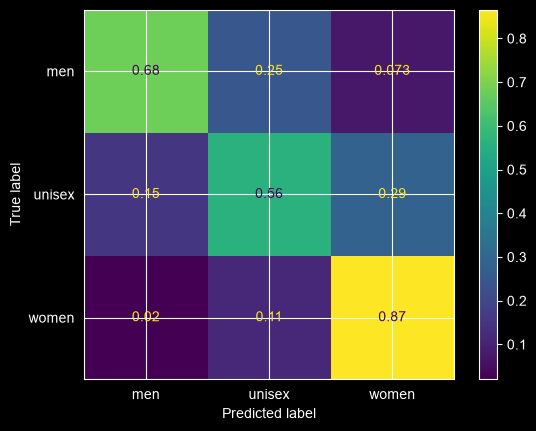

In [26]:
from sklearn.metrics import classification_report, recall_score, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))
print("Macro recall:", recall_score(y_test, y_pred, average="macro"))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true")
plt.show()

### Model 2: tylko perfumy męskie i damskie (men/women)

In [27]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# tylko men i women, bez unisex
df_mw = df[df["Gender"].isin(["men", "women"])].reset_index(drop=True)

df_mw["nuty"] = df_mw.apply(
    lambda r: [n.strip().lower()
               for kol in ["Top", "Middle", "Base"]
               for n in str(r[kol]).split(",") if n.strip()],
    axis=1
)

mlb_mw = MultiLabelBinarizer()
dane_mw = pd.DataFrame(
    mlb_mw.fit_transform(df_mw["nuty"]),
    columns=mlb_mw.classes_,
    index=[f"perfum{i}" for i in range(len(df_mw))]
)

y_mw = pd.Series(df_mw["Gender"].values, index=dane_mw.index)


In [28]:
df_mw

,url,Perfume,Brand,Country,Gender,Rating Value,Rating Count,Year,Top,Middle,Base,Perfumer1,Perfumer2,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5,nuty
0,https://www.fragrantica.com/perfume/gucci/gucc...,gucci-guilty-eau-pour-homme,gucci,Italy,men,3.82,611,2015.0,"lemon, bergamot","orris, snowberry, orange blossom","musk, patchouli",unknown,NaN,citrus,powdery,iris,fresh,musky,"[lemon, bergamot, orris, snowberry, orange blo..."
1,https://www.fragrantica.com/perfume/emanuel-un...,apparition-facets,emanuel-ungaro,France,women,3.75,53,2006.0,"bergamot, grapefruit","rose, hibiscus","musk, amber",francoise caron,NaN,citrus,floral,rose,fresh spicy,musky,"[bergamot, grapefruit, rose, hibiscus, musk, a..."
2,https://www.fragrantica.com/perfume/davidoff/c...,cool-water-frozen,davidoff,Switzerland,women,4.00,53,2001.0,"pineapple, peach, jasmine, rose, amber","lotus, lily-of-the-valley, quince, vetiver, bl...","water lily, orange, sandalwood, black currant",unknown,NaN,fruity,floral,sweet,fresh,white floral,"[pineapple, peach, jasmine, rose, amber, lotus..."
3,https://www.fragrantica.com/perfume/natura/ess...,essencial-oud,natura,Brazil,women,4.03,1049,2017.0,"pink pepper, black pepper, dried fruits, apricot","rose, priprioca, jasmine, praline, gurjan bals...","agarwood (oud), copaiba balm, vanilla, sandalw...",pierre-constantin guéros,verônica kato,woody,oud,balsamic,fresh spicy,powdery,"[pink pepper, black pepper, dried fruits, apri..."
4,https://www.fragrantica.com/perfume/calvin-kle...,eternity-night,calvin-klein,USA,women,3.74,164,2014.0,"pink pepper, plum, wild berries","jasmine, frangipani, wisteria","musk, sandalwood, tonka bean",unknown,NaN,floral,fruity,white floral,musky,sweet,"[pink pepper, plum, wild berries, jasmine, fra..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16360,https://www.fragrantica.com/perfume/marc-jacob...,daisy-skies,marc-jacobs,USA,women,3.87,113,2021.0,"mineral notes, violet leaves, quince","lotus, violet, jasmine","seaweed, musk, sandalwood",alberto morillas,NaN,aquatic,ozonic,floral,powdery,marine,"[mineral notes, violet leaves, quince, lotus, ..."
16361,https://www.fragrantica.com/perfume/khalis/oud...,oud-ateeq,khalis,UAE,men,3.93,28,NaN,"incense, vanilla, musk","caramel, agarwood (oud)","woody notes, mint",unknown,NaN,caramel,woody,amber,vanilla,oud,"[incense, vanilla, musk, caramel, agarwood (ou..."
16362,https://www.fragrantica.com/perfume/burberry/b...,burberry-her-blossom,burberry,UK,women,3.83,1045,2019.0,"mandarin orange, pink pepper","peony, plum blossom","musk, sandalwood",francis kurkdjian,NaN,floral,fresh,musky,rose,citrus,"[mandarin orange, pink pepper, peony, plum blo..."
16363,https://www.fragrantica.com/perfume/mugler/ang...,angel-glamorama,mugler,France,women,4.49,150,2014.0,"cassis, cotton candy, bergamot, jasmine, melon...","honey, plum, red berries, blackberry, jasmine,...","patchouli, chocolate, caramel, tonka bean, van...",olivier cresp,yves de chirin,sweet,fruity,patchouli,warm spicy,vanilla,"[cassis, cotton candy, bergamot, jasmine, melo..."


In [29]:
dane_mw

,absinthe,acai berry,accord eudora®,acerola,acerola blossom,acácia,african freesia petals,african geranium,african ginger,african orange flower,...,yellow plum,yellow poppy,yellow rose,yellow water lily,ylang ylang,ylang-ylang,yogurt,yuzu,zefir,zinnia
perfum0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
perfum16360,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum16361,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum16362,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
perfum16363,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Trening

In [30]:
X_train_mw, X_test_mw, y_train_mw, y_test_mw = train_test_split(
    dane_mw, y_mw, test_size=0.2, random_state=42, stratify=y_mw
)

model_mw = LogisticRegression(max_iter=2000)
model_mw.fit(X_train_mw, y_train_mw)

print("Accuracy men/women:", accuracy_score(y_test_mw, model_mw.predict(X_test_mw)))
print("Baseline (zawsze women):", (y_test_mw == "women").mean())


def przewidz_mw(nuty):
    nuty = [n.strip().lower() for n in nuty]
    wektor = pd.DataFrame(0, index=[0], columns=dane_mw.columns)

    znane = [n for n in nuty if n in dane_mw.columns]
    nieznane = [n for n in nuty if n not in dane_mw.columns]
    wektor[znane] = 1
    if nieznane:
        print("Model nie zna nut:", nieznane)

    plec = model_mw.predict(wektor)[0]
    pewnosc = dict(zip(model_mw.classes_, model_mw.predict_proba(wektor)[0].round(2)))
    return plec, pewnosc

Accuracy men/women: 0.9282004277421326
Baseline (zawsze women): 0.6950809654750993


#### Recall dla modelu men/women

              precision    recall  f1-score   support

         men       0.89      0.88      0.88       998
       women       0.95      0.95      0.95      2275

    accuracy                           0.93      3273
   macro avg       0.92      0.91      0.91      3273
weighted avg       0.93      0.93      0.93      3273

Macro recall: 0.9134801471074017


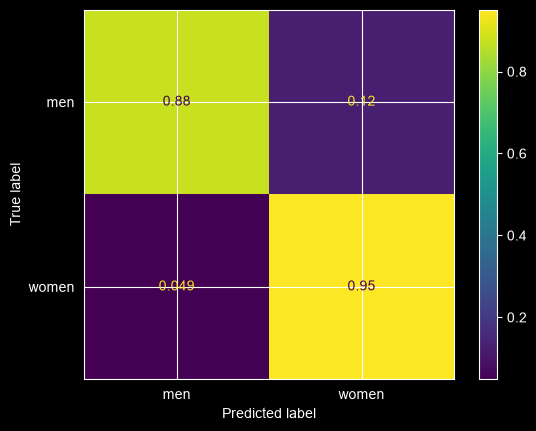

In [31]:
y_pred_mw = model_mw.predict(X_test_mw)
print(classification_report(y_test_mw, y_pred_mw, zero_division=0))
print("Macro recall:", recall_score(y_test_mw, y_pred_mw, average="macro"))
ConfusionMatrixDisplay.from_predictions(y_test_mw, y_pred_mw, normalize="true")
plt.show()

### Test na konkretnych perfumach: model men/women

In [32]:
# MĘSKIE

print("Castley (men):", przewidz_mw(["bergamot", "black pepper", "ginger", "grapefruit", "pepper", "neroli", "petitgrain", "rose", "akigalawood", "labdanum", "benzoin", "leather"]))
print("Dior Homme Parfum 2025 (men):", przewidz_mw(["iris", "amber", "patchouli", "vetiver"]))
print("Prada Paradigme (men):", przewidz_mw(["calabrian bergamot", "musk", "geranium", "rose geranium", "benzoin", "peru balsam", "guaiac wood"]))
print("Rayhaan Terra (men):", przewidz_mw(["cardamom", "elemi", "sichuan pepper", "bergamot", "lemon", "patchouli", "cumin", "coriander", "anise", "saffron", "wormwood", "orange blossom", "rose", "geranium", "frankincense", "vanilla", "amber", "benzoin", "opoponax", "oud", "labdanum", "birch", "musk", "ambergris", "maltol"]))
print("YSL Y Iced Cologne (men):", przewidz_mw(["mint", "ice", "sage", "patchouli", "ambroxan"]))

Castley (men): ('men', {'men': np.float64(0.94), 'women': np.float64(0.06)})
Dior Homme Parfum 2025 (men): ('men', {'men': np.float64(0.58), 'women': np.float64(0.42)})
Prada Paradigme (men): ('men', {'men': np.float64(0.54), 'women': np.float64(0.46)})
Rayhaan Terra (men): ('men', {'men': np.float64(0.94), 'women': np.float64(0.06)})
YSL Y Iced Cologne (men): ('men', {'men': np.float64(0.94), 'women': np.float64(0.06)})


In [33]:
# DAMSKIE

print("Valaya Exclusif (women):", przewidz_mw(["almond", "mandarin orange", "bergamot", "powdery notes", "orange blossom", "lily-of-the-valley", "lotus", "ambroxan", "vanilla", "akigalawood", "sandalwood", "white musk", "heliotrope"]))
print("Creed Fragaria (women):", przewidz_mw(["mandarin orange", "bergamot", "pink pepper", "strawberry", "violet", "cedar", "vetiver"]))
print("Miu Miu Miutine (women):", przewidz_mw(["strawberry", "citruses", "rose", "gardenia", "jasmine", "brown sugar", "patchouli", "bourbon vanilla", "oakmoss", "amber"]))
print("Lattafa Habik For Women (women):", przewidz_mw(["pear", "bergamot", "lily-of-the-valley", "freesia", "jasmine", "musk", "amber", "oakmoss"]))
print("Chloe Le Parfum (women):", przewidz_mw(["orange blossom", "rose", "vanilla", "tonka bean"]))

Valaya Exclusif (women): ('women', {'men': np.float64(0.01), 'women': np.float64(0.99)})
Creed Fragaria (women): ('women', {'men': np.float64(0.26), 'women': np.float64(0.74)})
Miu Miu Miutine (women): ('women', {'men': np.float64(0.0), 'women': np.float64(1.0)})
Lattafa Habik For Women (women): ('women', {'men': np.float64(0.02), 'women': np.float64(0.98)})
Chloe Le Parfum (women): ('women', {'men': np.float64(0.04), 'women': np.float64(0.96)})


### Te same przykłady (plus perfumy unisex) w modelu men/women/unisex

In [34]:
# MĘSKIE

print("Castley:", przewidz(["bergamot", "black pepper", "ginger", "grapefruit", "pepper", "neroli", "petitgrain", "rose", "akigalawood", "labdanum", "benzoin", "leather"]))
print("Dior Homme Parfum 2025:", przewidz(["iris", "amber", "patchouli", "vetiver"]))
print("Prada Paradigme:", przewidz(["calabrian bergamot", "musk", "geranium", "rose geranium", "benzoin", "peru balsam", "guaiac wood"]))
print("Rayhaan Terra:", przewidz(["cardamom", "elemi", "sichuan pepper", "bergamot", "lemon", "patchouli", "cumin", "coriander", "anise", "saffron", "wormwood", "orange blossom", "rose", "geranium", "frankincense", "vanilla", "amber", "benzoin", "opoponax", "oud", "labdanum", "birch", "musk", "ambergris", "maltol"]))
print("YSL Y Iced Cologne:", przewidz(["mint", "ice", "sage", "patchouli", "ambroxan"]))

Castley: ('unisex', {'men': np.float64(0.37), 'unisex': np.float64(0.6), 'women': np.float64(0.03)})
Dior Homme Parfum 2025: ('unisex', {'men': np.float64(0.3), 'unisex': np.float64(0.37), 'women': np.float64(0.33)})
Prada Paradigme: ('unisex', {'men': np.float64(0.08), 'unisex': np.float64(0.85), 'women': np.float64(0.07)})
Rayhaan Terra: ('unisex', {'men': np.float64(0.05), 'unisex': np.float64(0.95), 'women': np.float64(0.0)})
YSL Y Iced Cologne: ('men', {'men': np.float64(0.56), 'unisex': np.float64(0.34), 'women': np.float64(0.1)})


In [35]:
# DAMSKIE

print("Valaya Exclusif:", przewidz(["almond", "mandarin orange", "bergamot", "powdery notes", "orange blossom", "lily-of-the-valley", "lotus", "ambroxan", "vanilla", "akigalawood", "sandalwood", "white musk", "heliotrope"]))
print("Creed Fragaria:", przewidz(["mandarin orange", "bergamot", "pink pepper", "strawberry", "violet", "cedar", "vetiver"]))
print("Miu Miu Miutine:", przewidz(["strawberry", "citruses", "rose", "gardenia", "jasmine", "brown sugar", "patchouli", "bourbon vanilla", "oakmoss", "amber"]))
print("Lattafa Habik For Women:", przewidz(["pear", "bergamot", "lily-of-the-valley", "freesia", "jasmine", "musk", "amber", "oakmoss"]))
print("Chloe Le Parfum:", przewidz(["orange blossom", "rose", "vanilla", "tonka bean"]))

Valaya Exclusif: ('women', {'men': np.float64(0.0), 'unisex': np.float64(0.39), 'women': np.float64(0.61)})
Creed Fragaria: ('women', {'men': np.float64(0.12), 'unisex': np.float64(0.31), 'women': np.float64(0.58)})
Miu Miu Miutine): ('women', {'men': np.float64(0.0), 'unisex': np.float64(0.27), 'women': np.float64(0.73)})
Lattafa Habik For Women: ('women', {'men': np.float64(0.03), 'unisex': np.float64(0.11), 'women': np.float64(0.87)})
Chloe Le Parfum: ('women', {'men': np.float64(0.05), 'unisex': np.float64(0.2), 'women': np.float64(0.75)})


In [36]:
# UNISEX

print("PdM Valero:", przewidz(["citron", "bergamot", "juniper", "lavender", "geranium", "nutmeg", "cypress", "ambroxan", "patchouli", "sandalwood"]))
print("PdM Eragon:", przewidz(["cardamom", "mandarin orange", "bergamot", "cinnamon", "cypriol", "davana", "vanilla bean", "tonka bean", "leather", "patchouli"]))
print("PdM Carios:", przewidz(["saffron", "mandarin orange", "pink pepper", "bergamot", "black pepper", "geranium", "red thyme", "ambroxan", "tonka bean", "vetiver", "cedar"]))
print("Amouage Decision:", przewidz(["cardamom", "bergamot", "pink pepper", "frankincense", "myrrh", "juniper berries", "vanilla", "cedar", "patchouli"]))
print("Amouage Existence:", przewidz(["aldehydes", "lily-of-the-valley", "rose", "frankincense", "labdanum", "white musk", "benzoin", "ambergris"]))
print("Xerjoff Torino25:", przewidz(["rhubarb", "grapefruit", "saffron", "ginger", "suede", "juniper", "leather", "vetiver", "amber", "musk"]))

PdM Valero: ('men', {'men': np.float64(0.78), 'unisex': np.float64(0.22), 'women': np.float64(0.0)})
PdM Eragon: ('men', {'men': np.float64(0.54), 'unisex': np.float64(0.43), 'women': np.float64(0.03)})
PdM Carios: ('men', {'men': np.float64(0.75), 'unisex': np.float64(0.23), 'women': np.float64(0.03)})
Amouage Decision: ('men', {'men': np.float64(0.5), 'unisex': np.float64(0.43), 'women': np.float64(0.07)})
Amouage Existence: ('unisex', {'men': np.float64(0.02), 'unisex': np.float64(0.68), 'women': np.float64(0.3)})
Xerjoff Torino25: ('men', {'men': np.float64(0.71), 'unisex': np.float64(0.29), 'women': np.float64(0.01)})


### Wniosek
Hipoteza się potwierdziła. Bez klasy unisex accuracy rośnie z **0,73** do **0,93**, czyli model bardzo dobrze odróżnia perfumy męskie od damskich. Po dodaniu unisex wyniki wyraźnie spadają, bo nuty w perfumach unisex często pokrywają się z nutami perfum męskich i damskich. Z samego składu trudno więc jednoznacznie ustalić, dla kogo zapach zaprojektowano.

### Recall vs accuracy
Ważony recall (*weighted avg*: 0,73 i 0,93) jest z definicji równy accuracy, dlatego bardziej miarodajny jest **recall makro**, który traktuje każdą klasę jednakowo. Jest on tylko trochę niższy od accuracy (0,70 vs 0,73 oraz 0,91 vs 0,93). Oznacza to, że niezbalansowanie klas (najwięcej perfum damskich) nie zawyża mocno wyniku, a model nie „oszukuje”, przewidując głównie klasę dominującą.

Recall dla poszczególnych klas (model men/women/unisex → model men/women) pokazuje jednak, gdzie leży problem:
- **women:** 0,87 → 0,95 (najłatwiejsza klasa w obu modelach),
- **men:** 0,68 → 0,88 (największy spadek po dodaniu unisex: model często myli perfumy męskie z unisex),
- **unisex:** 0,56 (najsłabszy wynik, prawie połowa perfum unisex jest źle klasyfikowana).

Widać to też na konkretnych przykładach: w modelu trzyklasowym 4 z 5 perfum męskich trafiło do unisex, a 5 z 6 perfum unisex do men. Granica między perfumami męskimi a unisex jest więc dla modelu najbardziej rozmyta, a damskie mają wyraźniejszy „profil” nut.